# IPL Match Winner Prediction

## Predictive Modeling Pipeline

This project aims to build a machine learning classification pipeline to predict the winning team of an IPL match using pre-match information and match-level features.

The project covers data loading, data cleaning, feature preparation, categorical encoding, model training, evaluation, cross-validation, hyperparameter tuning, and final model selection.

## 1. Business Problem

### Business Question

Can we predict the winning team of an IPL match using information available before or at the start of the match?

### Objective

The objective of this project is to develop a machine learning classification model that predicts the winning team based on available match-level information such as the participating teams, venue, city, season, and toss-related information.

The model performance will be evaluated using multiple classification metrics, with F1-score as the primary evaluation metric.

## 2. Problem Type

This is a **Multiclass Classification** problem.

The target variable is `winner`, which contains the name of the team that won the match. Since the model needs to predict one class from multiple possible team categories, this problem is treated as multiclass classification.

## 3. Features and Target

### Target Variable (y)

`winner`

The model will predict the winning team of the IPL match.

### Feature Variables (X)

The initial candidate features are:

- `season`
- `city`
- `match_type`
- `venue`
- `team1`
- `team2`
- `toss_winner`
- `toss_decision`
- `super_over`

These features represent information available before or around the start of the match.

### Features Excluded

The following columns are excluded because they are either the target variable itself or contain post-match information:

- `winner`
- `player_of_match`
- `result`
- `result_margin`
- `target_runs`
- `target_overs`
- `method`

These columns are not used as predictors to avoid data leakage.

In [46]:
import pandas as pd
import numpy as np

matches = pd.read_csv("matches.csv")

print("Dataset loaded successfully!")
print("Shape:", matches.shape)


Dataset loaded successfully!
Shape: (1095, 20)


In [47]:
matches.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [48]:
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [49]:
matches.columns.tolist()

['id',
 'season',
 'city',
 'date',
 'match_type',
 'player_of_match',
 'venue',
 'team1',
 'team2',
 'toss_winner',
 'toss_decision',
 'winner',
 'result',
 'result_margin',
 'target_runs',
 'target_overs',
 'super_over',
 'method',
 'umpire1',
 'umpire2']

In [50]:
matches.describe(include="all")

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
count,1.095000e+03,1095,1044,1095,1095,1090,1095,1095,1095,1095,1095,1090,1095,1076.000000,1092.000000,1092.000000,1095,21,1095,1095
unique,NaN,17,36,823,8,291,58,19,19,19,2,19,4,NaN,NaN,NaN,2,1,62,62
top,NaN,2013,Mumbai,2008-04-26,League,AB de Villiers,Eden Gardens,Royal Challengers Bangalore,Mumbai Indians,Mumbai Indians,field,Mumbai Indians,wickets,NaN,NaN,NaN,N,D/L,AK Chaudhary,S Ravi
freq,NaN,76,173,2,1029,25,77,135,138,143,704,144,578,NaN,NaN,NaN,1081,21,115,83
mean,9.048283e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.259294,165.684066,19.759341,NaN,NaN,NaN,NaN
std,3.677402e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.787444,33.427048,1.581108,NaN,NaN,NaN,NaN
min,3.359820e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,43.000000,5.000000,NaN,NaN,NaN,NaN
25%,5.483315e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,146.000000,20.000000,NaN,NaN,NaN,NaN
50%,9.809610e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,166.000000,20.000000,NaN,NaN,NaN,NaN
75%,1.254062e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000,187.000000,20.000000,NaN,NaN,NaN,NaN


# Step 2: Prepare the Features

## Step 2A: Select X and y

In [51]:
# Remove rows where the target variable is missing
matches_model = matches.dropna(subset=['winner']).copy()

# Define features (X) and target (y)
X = matches_model[
    [
        'season',
        'city',
        'match_type',
        'venue',
        'team1',
        'team2',
        'toss_winner',
        'toss_decision',
        'super_over'
    ]
]

y = matches_model['winner']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1090, 9)
Target shape: (1090,)


## Step 2B: Check Target Distribution

In [52]:
# Check the distribution of the target variable
print(y.value_counts())

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    116
Rajasthan Royals               112
Sunrisers Hyderabad             88
Kings XI Punjab                 88
Delhi Daredevils                67
Delhi Capitals                  48
Deccan Chargers                 29
Gujarat Titans                  28
Punjab Kings                    24
Lucknow Super Giants            24
Gujarat Lions                   13
Pune Warriors                   12
Rising Pune Supergiant          10
Royal Challengers Bengaluru      7
Kochi Tuskers Kerala             6
Rising Pune Supergiants          5
Name: count, dtype: int64


In [53]:
# Check the number of unique classes
print("Number of classes:", y.nunique())

Number of classes: 19


## Step 2C: Train-Test Split

In [54]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (872, 9)
X_test shape: (218, 9)
y_train shape: (872,)
y_test shape: (218,)


## Step 2D: Encode Categorical Features

In [55]:
from sklearn.preprocessing import OneHotEncoder

# Create the encoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit the encoder only on training data
X_train_encoded = encoder.fit_transform(X_train)

# Transform test data using the same fitted encoder
X_test_encoded = encoder.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (872, 181)
Encoded testing shape: (218, 181)


# Step 3: Prepare the Modeling Pipeline

## Step 3A: Building Preprocessing Pipeline

In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# List of categorical features
categorical_features = X.columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Step 3B: Logistic Regression

In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=2000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## Step 3C: Logistic Regression Evaluation

The Logistic Regression model is evaluated using Accuracy, Precision, Recall, and Macro F1-score. Since this is a multiclass classification problem with multiple IPL teams, Macro F1-score is used as the primary evaluation metric.

In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

precision_logistic = precision_score(
    y_test,
    y_pred_logistic,
    average='macro',
    zero_division=0
)

recall_logistic = recall_score(
    y_test,
    y_pred_logistic,
    average='macro',
    zero_division=0
)

f1_logistic = f1_score(
    y_test,
    y_pred_logistic,
    average='macro',
    zero_division=0
)

# Print results
print("Logistic Regression Results")
print("----------------------------")
print(f"Accuracy : {accuracy_logistic:.4f}")
print(f"Precision: {precision_logistic:.4f}")
print(f"Recall   : {recall_logistic:.4f}")
print(f"Macro F1 : {f1_logistic:.4f}")

Logistic Regression Results
----------------------------
Accuracy : 0.5917
Precision: 0.5555
Recall   : 0.4712
Macro F1 : 0.4878


## Step 3D: Confusion Matrix

<Figure size 1200x1000 with 0 Axes>

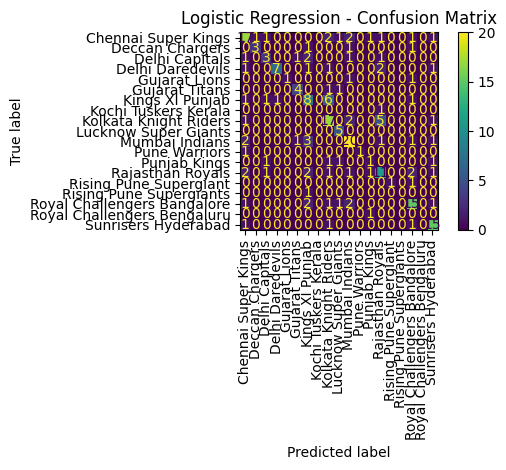

In [59]:
# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic, labels=logistic_model.classes_)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
)

disp.plot(
    xticks_rotation=90,
    values_format='d'
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 3E: Train Decision Tree Classifier

In [60]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        random_state=42,
        max_depth=10
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = decision_tree_model.predict(X_test)

print("Decision Tree Classifier model trained successfully.")

Decision Tree Classifier model trained successfully.


## Step 3F: Evaluate Decision Tree

In [61]:
# Calculate Decision Tree evaluation metrics

accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    average='macro',
    zero_division=0
)

recall_dt = recall_score(
    y_test,
    y_pred_dt,
    average='macro',
    zero_division=0
)

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    average='macro',
    zero_division=0
)

# Print results
print("Decision Tree Results")
print("---------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"Macro F1 : {f1_dt:.4f}")

Decision Tree Results
---------------------
Accuracy : 0.3853
Precision: 0.2552
Recall   : 0.2314
Macro F1 : 0.2167


## Step 3G: Decision Tree Classification Report

In [62]:
# Generate classification report for Decision Tree

print("Decision Tree Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_dt,
        zero_division=0
    )
)

Decision Tree Classification Report
------------------------------------
                             precision    recall  f1-score   support

        Chennai Super Kings       0.58      0.39      0.47        28
            Deccan Chargers       0.00      0.00      0.00         6
             Delhi Capitals       0.13      0.67      0.21         9
           Delhi Daredevils       0.55      0.46      0.50        13
              Gujarat Lions       0.00      0.00      0.00         3
             Gujarat Titans       0.00      0.00      0.00         6
            Kings XI Punjab       0.30      0.44      0.36        18
       Kochi Tuskers Kerala       0.00      0.00      0.00         1
      Kolkata Knight Riders       0.47      0.54      0.50        26
       Lucknow Super Giants       1.00      0.20      0.33         5
             Mumbai Indians       0.45      0.31      0.37        29
              Pune Warriors       0.00      0.00      0.00         2
               Punjab Kings  

## Step 3H: Decision Tree Confusion Matrix

<Figure size 1200x1000 with 0 Axes>

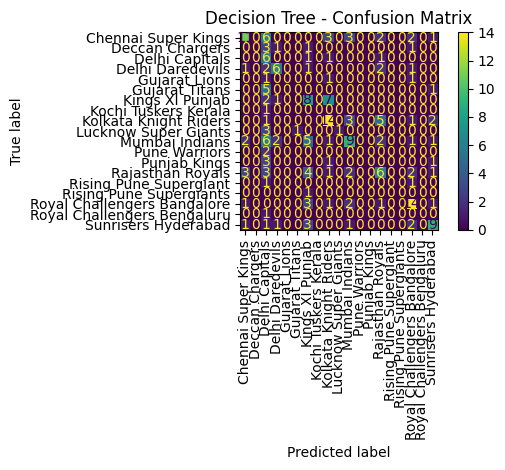

In [63]:
# Create confusion matrix for Decision Tree

cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=decision_tree_model.classes_
)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=decision_tree_model.classes_
)

disp_dt.plot(
    xticks_rotation=90,
    values_format='d'
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 3I: Train Random Forest Classifier

In [64]:
# Step 3I: Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Classifier model trained successfully.")

Random Forest Classifier model trained successfully.


## Step 3J: Make Predictions using the Random Forest Model

In [65]:
# Step 3J: Make predictions using Random Forest

y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions generated successfully.")

Random Forest predictions generated successfully.


## Step 3K: Random Forest Evaluation Metrics

In [66]:
# Step 3K: Random Forest Evaluation Metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='macro', zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, average='macro', zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, average='macro', zero_division=0)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"Macro F1 : {f1_rf:.4f}")

Random Forest Results
---------------------
Accuracy : 0.5183
Precision: 0.4724
Recall   : 0.5229
Macro F1 : 0.4759


## Step 3L: Random Forest Classification Report

In [67]:
# Step 3L: Random Forest Classification Report

from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("------------------------------------")

print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

Random Forest Classification Report
------------------------------------
                             precision    recall  f1-score   support

        Chennai Super Kings       0.59      0.57      0.58        28
            Deccan Chargers       0.75      0.50      0.60         6
             Delhi Capitals       0.60      0.67      0.63         9
           Delhi Daredevils       0.45      0.38      0.42        13
              Gujarat Lions       1.00      0.67      0.80         3
             Gujarat Titans       0.56      0.83      0.67         6
            Kings XI Punjab       0.40      0.44      0.42        18
       Kochi Tuskers Kerala       0.33      1.00      0.50         1
      Kolkata Knight Riders       0.50      0.54      0.52        26
       Lucknow Super Giants       0.45      1.00      0.62         5
             Mumbai Indians       0.54      0.52      0.53        29
              Pune Warriors       0.00      0.00      0.00         2
               Punjab Kings  

## Step 3M: Random Forest Confusion Matrix

<Figure size 1200x1000 with 0 Axes>

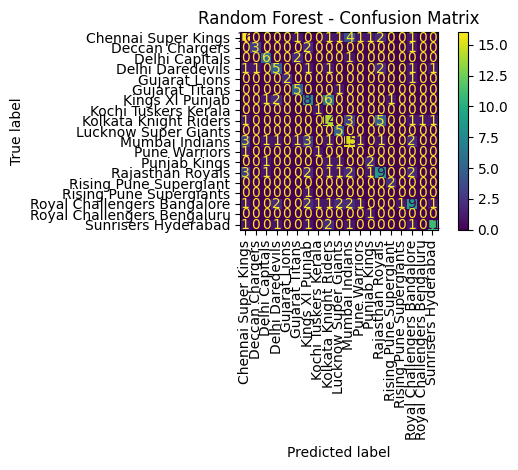

In [68]:
# Step 3M: Random Forest Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=rf_model.classes_
)

plt.figure(figsize=(12, 10))

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=rf_model.classes_
)

disp_rf.plot(
    xticks_rotation=90,
    values_format='d'
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 4: Improvre and Validate the Best Model

## Step 4A: Create a Pipeline for Logistic Regression

In [69]:
# Step 4A: Create a complete Pipeline
# Preprocessing + Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create pipeline
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Logistic Regression Pipeline created successfully.")

Logistic Regression Pipeline created successfully.


## Step 4B: 5-Fold Stratified Cross-Validation using Macro F1 as primary metric

In [70]:
# Step 4B: 5-Fold Stratified Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation using Macro F1
cv_scores = cross_val_score(
    logistic_pipeline,
    X,
    y,
    cv=cv,
    scoring='f1_macro'
)

# Display results
print("5-Fold Cross-Validation Results")
print("--------------------------------")
print("Fold Scores:", cv_scores)
print(f"Mean Macro F1: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

5-Fold Cross-Validation Results
--------------------------------
Fold Scores: [0.36408622 0.4502628  0.37078114 0.37723345 0.35321718]
Mean Macro F1: 0.3831
Standard Deviation: 0.0345


## Step 4C: Model Comparison

In [71]:
# Model Comparison

model_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [0.5917, 0.3853, 0.5183],
    'Precision': [0.5555, 0.2552, 0.4724],
    'Recall': [0.4712, 0.2314, 0.5229],
    'Macro F1': [0.4878, 0.2167, 0.4759]
})

display(model_results)

,Model,Accuracy,Precision,Recall,Macro F1
0,Logistic Regression,0.5917,0.5555,0.4712,0.4878
1,Decision Tree,0.3853,0.2552,0.2314,0.2167
2,Random Forest,0.5183,0.4724,0.5229,0.4759


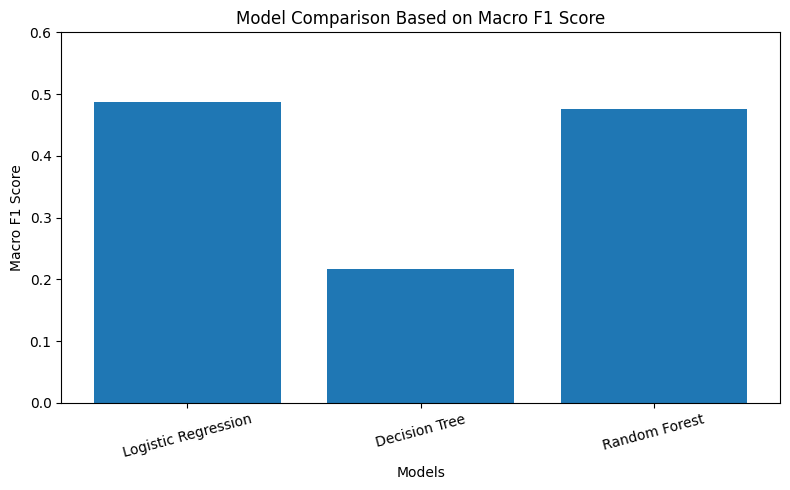

In [72]:
import matplotlib.pyplot as plt

# Model names
models = ['Logistic Regression', 'Decision Tree', 'Random Forest']

# Macro F1 scores
macro_f1 = [0.4878, 0.2167, 0.4759]

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(models, macro_f1)

plt.title('Model Comparison Based on Macro F1 Score')
plt.xlabel('Models')
plt.ylabel('Macro F1 Score')

plt.ylim(0, 0.6)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

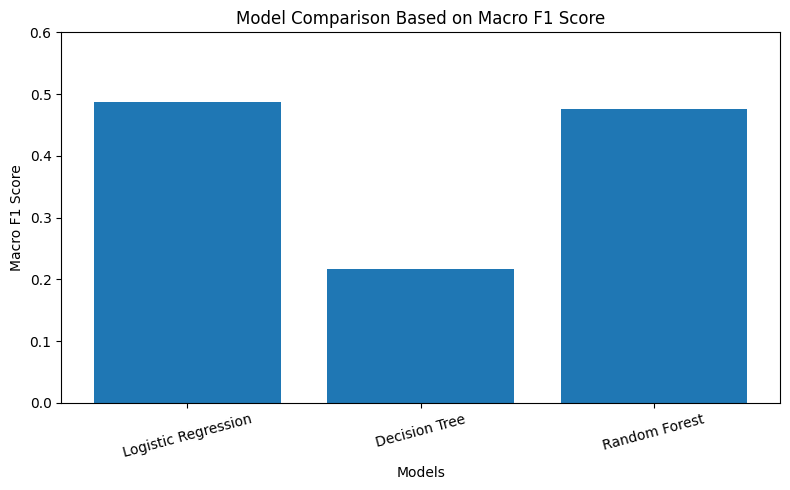

In [73]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Decision Tree', 'Random Forest']

macro_f1 = [0.4878, 0.2167, 0.4759]

plt.figure(figsize=(8, 5))
plt.bar(models, macro_f1)

plt.title('Model Comparison Based on Macro F1 Score')
plt.xlabel('Models')
plt.ylabel('Macro F1 Score')

plt.ylim(0, 0.6)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## Step 4D: Best Model Selection

Based on the initial test-set evaluation, Logistic Regression achieved the highest Macro F1-score of 0.4878 among the three evaluated models. Therefore, Logistic Regression is currently the best-performing model based on the primary evaluation metric.

However, the final model selection will be made after cross-validation and hyperparameter tuning to determine whether the model's performance can be improved and generalized more reliably to unseen data.

## Step 4E: Hyperparameter Tuning

In [74]:
# Step 4E: Hyperparameter Tuning using GridSearchCV

from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['lbfgs', 'newton-cg']
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

# Fit GridSearchCV on training data only
grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed successfully.")
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", grid_search.best_score_)

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Hyperparameter tuning completed successfully.
Best Parameters: {'classifier__C': 100, 'classifier__solver': 'lbfgs'}
Best Cross-Validation Macro F1: 0.4553668118201471


## Step 4F: Evaluate the Tuned Model

In [75]:
# Get the best tuned model
best_model = grid_search.best_estimator_

# Make predictions on the test data
y_pred_tuned = best_model.predict(X_test)

# Calculate evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, average='macro', zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, average='macro', zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, average='macro', zero_division=0)

print("Tuned Logistic Regression Results")
print("--------------------------------")
print(f"Accuracy : {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall   : {recall_tuned:.4f}")
print(f"Macro F1 : {f1_tuned:.4f}")

Tuned Logistic Regression Results
--------------------------------
Accuracy : 0.5183
Precision: 0.5344
Recall   : 0.5906
Macro F1 : 0.5526


## Step 4G: Final Model Selection

In [76]:
# Final Model Selection

print("Final Model Selection")
print("---------------------")

print("Selected Model: Tuned Logistic Regression")
print("Reason: Highest Test Macro F1 Score")
print(f"Test Macro F1: {f1_tuned:.4f}")

Final Model Selection
---------------------
Selected Model: Tuned Logistic Regression
Reason: Highest Test Macro F1 Score
Test Macro F1: 0.5526


## Final Model Selection – Observation

The Tuned Logistic Regression model was selected as the final model because it achieved the highest test-set Macro F1 score of **0.5526** among all evaluated models. Hyperparameter tuning improved the Macro F1 score from **0.4878** to **0.5526**, showing improved balanced classification performance across the IPL teams.

In [77]:
# Check class distribution in the training target
print(y_train.value_counts())

# Check percentage distribution
print("\nClass Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

winner
Mumbai Indians                 115
Chennai Super Kings            110
Kolkata Knight Riders          105
Royal Challengers Bangalore     93
Rajasthan Royals                90
Kings XI Punjab                 70
Sunrisers Hyderabad             70
Delhi Daredevils                54
Delhi Capitals                  39
Deccan Chargers                 23
Gujarat Titans                  22
Lucknow Super Giants            19
Punjab Kings                    19
Pune Warriors                   10
Gujarat Lions                   10
Rising Pune Supergiant           8
Royal Challengers Bengaluru      6
Kochi Tuskers Kerala             5
Rising Pune Supergiants          4
Name: count, dtype: int64

Class Percentage:
winner
Mumbai Indians                 13.19
Chennai Super Kings            12.61
Kolkata Knight Riders          12.04
Royal Challengers Bangalore    10.67
Rajasthan Royals               10.32
Kings XI Punjab                 8.03
Sunrisers Hyderabad             8.03
Delhi Daredevils 

## Rebalance the training data

In [78]:
from imblearn.over_sampling import RandomOverSampler

# Create the oversampler
ros = RandomOverSampler(random_state=42)

# Oversample training data only
X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train,
    y_train
)

print("Original training shape:", X_train.shape)
print("Resampled training shape:", X_train_resampled.shape)

print("\nClass distribution after oversampling:")
print(y_train_resampled.value_counts())

Original training shape: (872, 9)
Resampled training shape: (2185, 9)

Class distribution after oversampling:
winner
Lucknow Super Giants           115
Royal Challengers Bangalore    115
Sunrisers Hyderabad            115
Chennai Super Kings            115
Delhi Capitals                 115
Kolkata Knight Riders          115
Delhi Daredevils               115
Kings XI Punjab                115
Punjab Kings                   115
Deccan Chargers                115
Rajasthan Royals               115
Mumbai Indians                 115
Gujarat Titans                 115
Pune Warriors                  115
Rising Pune Supergiant         115
Gujarat Lions                  115
Royal Challengers Bengaluru    115
Rising Pune Supergiants        115
Kochi Tuskers Kerala           115
Name: count, dtype: int64


## Rebalancing – Observation

The target variable `winner` was highly imbalanced, with class proportions ranging from 0.46% to 13.19%. Since the minority class was below the 35% threshold, Random Oversampling was applied to the training data only. The training set increased from 872 to 2,185 samples, with all 19 classes balanced to 115 samples each. The test set was kept unchanged to ensure unbiased model evaluation and avoid data leakage.

In [79]:
# Transform the oversampled training data using the existing preprocessor
X_train_resampled_encoded = preprocessor.fit_transform(X_train_resampled)

# Transform the original test data
X_test_encoded = preprocessor.transform(X_test)

print("Resampled training data encoded successfully.")
print("Encoded training shape:", X_train_resampled_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Resampled training data encoded successfully.
Encoded training shape: (2185, 181)
Encoded testing shape: (218, 181)


In [80]:
# Train Logistic Regression on balanced training data

from sklearn.linear_model import LogisticRegression

lr_balanced = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
lr_balanced.fit(
    X_train_resampled_encoded,
    y_train_resampled
)

print("Logistic Regression trained successfully on balanced data.")

Logistic Regression trained successfully on balanced data.


In [81]:
# Make predictions on the untouched test data

y_pred_balanced = lr_balanced.predict(X_test_encoded)

print("Predictions generated successfully.")

Predictions generated successfully.


In [82]:
# Evaluate Logistic Regression after oversampling

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_balanced = accuracy_score(y_test, y_pred_balanced)

precision_balanced = precision_score(
    y_test,
    y_pred_balanced,
    average='macro',
    zero_division=0
)

recall_balanced = recall_score(
    y_test,
    y_pred_balanced,
    average='macro',
    zero_division=0
)

f1_balanced = f1_score(
    y_test,
    y_pred_balanced,
    average='macro',
    zero_division=0
)

print("Logistic Regression Results After Oversampling")
print("-----------------------------------------------")
print(f"Accuracy : {accuracy_balanced:.4f}")
print(f"Precision: {precision_balanced:.4f}")
print(f"Recall   : {recall_balanced:.4f}")
print(f"Macro F1 : {f1_balanced:.4f}")

Logistic Regression Results After Oversampling
-----------------------------------------------
Accuracy : 0.5780
Precision: 0.4889
Recall   : 0.5637
Macro F1 : 0.5079


## Rebalancing – Model Comparison

Random Oversampling was applied to the training data because the target variable was highly imbalanced. The model was then evaluated on the original, untouched test set.

After oversampling, Accuracy improved from **0.5183 to 0.5780**. However, the Macro F1 score decreased from **0.5526 to 0.5079**. Since Macro F1 is the primary evaluation metric, the **Tuned Logistic Regression model without oversampling** remains the preferred final model based on the current test-set results.

## Final Model Comparison

In [83]:
# Final Model Comparison

final_model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Logistic Regression',
        'Logistic Regression + Oversampling'
    ],
    'Accuracy': [
        0.5917,
        0.3853,
        0.5183,
        0.5183,
        0.5780
    ],
    'Precision': [
        0.5555,
        0.2552,
        0.4724,
        0.5344,
        0.4889
    ],
    'Recall': [
        0.4712,
        0.2314,
        0.5229,
        0.5906,
        0.5637
    ],
    'Macro F1': [
        0.4878,
        0.2167,
        0.4759,
        0.5526,
        0.5079
    ]
})

display(final_model_comparison)

,Model,Accuracy,Precision,Recall,Macro F1
0,Logistic Regression,0.5917,0.5555,0.4712,0.4878
1,Decision Tree,0.3853,0.2552,0.2314,0.2167
2,Random Forest,0.5183,0.4724,0.5229,0.4759
3,Tuned Logistic Regression,0.5183,0.5344,0.5906,0.5526
4,Logistic Regression + Oversampling,0.5780,0.4889,0.5637,0.5079


## Validation Summary

- **Original Logistic Regression – 5-Fold CV Mean Macro F1:** 0.3831
- **Tuned Logistic Regression – Best 5-Fold CV Macro F1:** 0.4554
- **Tuned Logistic Regression – Test Macro F1:** 0.5526
- **Logistic Regression + Oversampling – Test Macro F1:** 0.5079

## Final Model Comparison – Observation

Five model configurations were evaluated using Accuracy, Precision, Recall, and Macro F1. Since Macro F1 is the primary evaluation metric, the Tuned Logistic Regression achieved the highest Macro F1 score of **0.5526** on the test set. The Decision Tree performed the weakest, with a Macro F1 score of **0.2167**.

Random Oversampling improved the Accuracy of Logistic Regression to **0.5780**, but its Macro F1 score of **0.5079** was lower than the Tuned Logistic Regression's **0.5526**. Therefore, based on the test-set results, Tuned Logistic Regression provides the best overall balanced classification performance among the evaluated models.

## Final Model Recommendation

Based on the evaluation results, the **Tuned Logistic Regression** model is recommended as the final model for this project. It achieved the highest **Macro F1 score of 0.5526** on the test set among all evaluated model configurations.

The model was tuned using **5-fold cross-validation**, with `C` and `solver` as the key hyperparameters. Although Random Oversampling improved the test accuracy to **0.5780**, its Macro F1 score of **0.5079** was lower than the tuned model's **0.5526**.

Since **Macro F1 is the primary evaluation metric**, the Tuned Logistic Regression model provides the best overall balanced performance across the 19 IPL team classes based on the current test-set results. Therefore, it is selected as the final recommended model.

In [84]:
# Step 6: Final Classification Report

from sklearn.metrics import classification_report

print("Final Model - Tuned Logistic Regression")
print("Classification Report")
print("----------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

Final Model - Tuned Logistic Regression
Classification Report
----------------------------------------
                             precision    recall  f1-score   support

        Chennai Super Kings       0.50      0.50      0.50        28
            Deccan Chargers       0.43      0.50      0.46         6
             Delhi Capitals       0.14      0.11      0.12         9
           Delhi Daredevils       0.69      0.69      0.69        13
              Gujarat Lions       0.67      0.67      0.67         3
             Gujarat Titans       0.43      0.50      0.46         6
            Kings XI Punjab       0.29      0.33      0.31        18
       Kochi Tuskers Kerala       0.50      1.00      0.67         1
      Kolkata Knight Riders       0.44      0.46      0.45        26
       Lucknow Super Giants       0.44      0.80      0.57         5
             Mumbai Indians       0.64      0.62      0.63        29
              Pune Warriors       0.00      0.00      0.00         2

### Final Classification Report – Observation

The final Tuned Logistic Regression model achieved an accuracy of **51.83%** and a Macro F1 score of **0.5526** on the test set. The Macro F1 score indicates that the model provides a reasonable balance between precision and recall across the 19 IPL team classes. Performance varies between teams, with some classes showing stronger results than others. This variation is expected because the dataset contains an imbalanced number of matches for different teams, and some teams have very few samples in the test set.

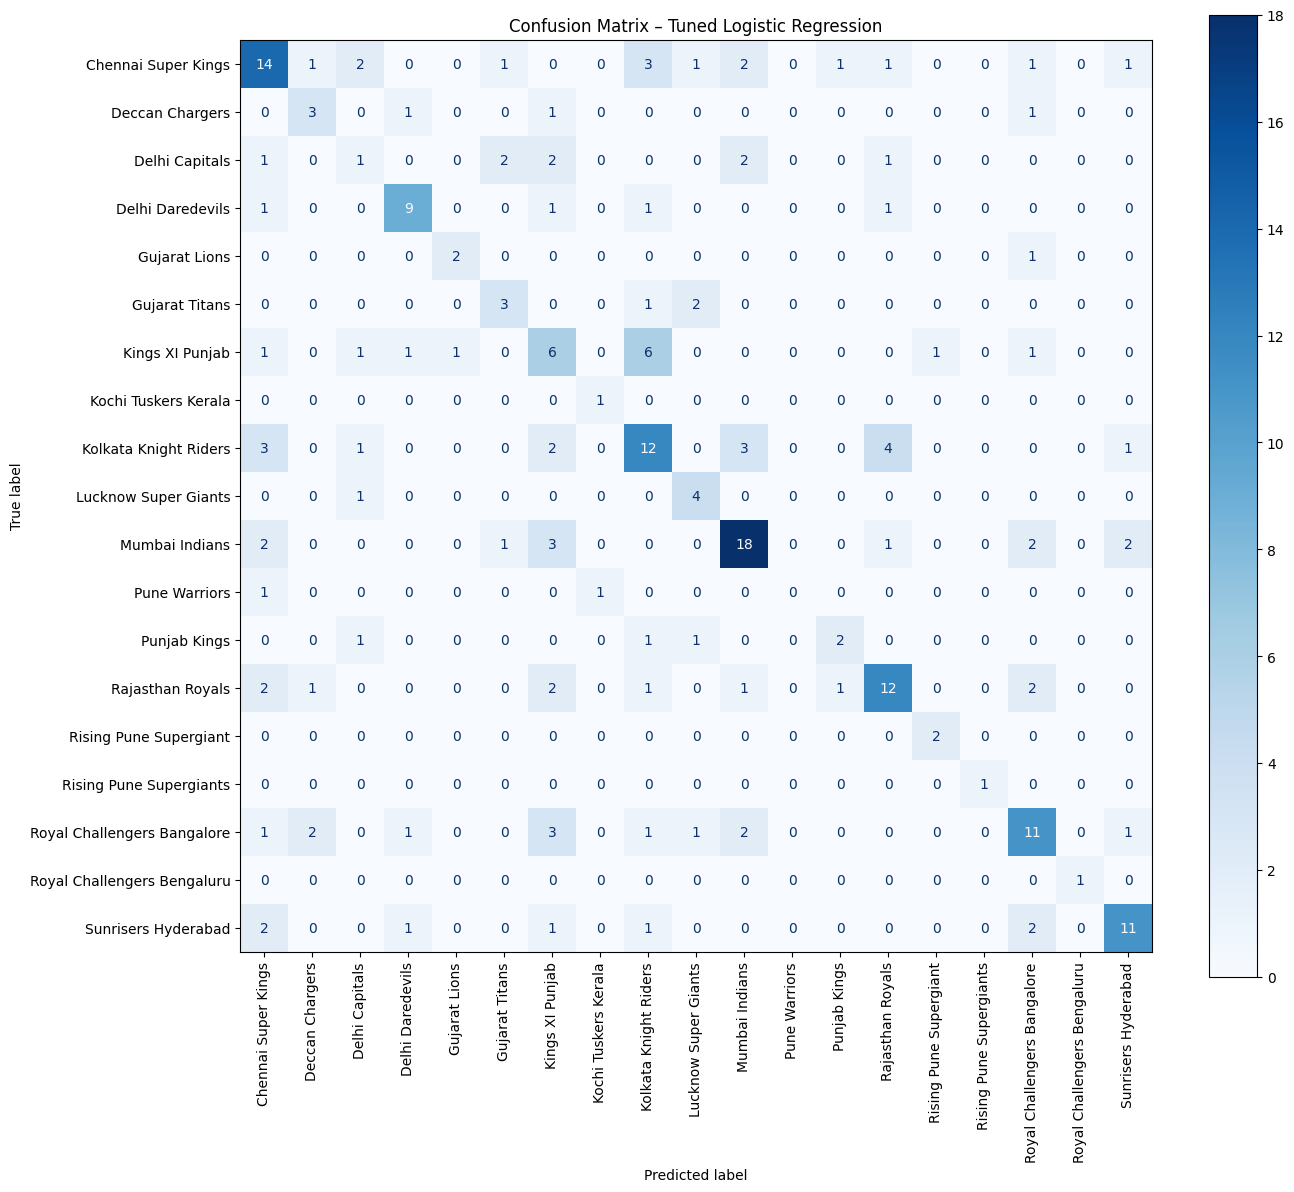

In [85]:
# Step 7: Final Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get class labels
class_names = sorted(y_test.unique())

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned, labels=class_names)

# Plot confusion matrix
plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=90,
    cmap='Blues',
    ax=plt.gca()
)

plt.title('Confusion Matrix – Tuned Logistic Regression')
plt.tight_layout()
plt.show()

### Final Confusion Matrix – Observation

The confusion matrix shows that the Tuned Logistic Regression model correctly identifies several teams with relatively good performance, including Mumbai Indians, Kolkata Knight Riders, Rajasthan Royals, Royal Challengers Bangalore, and Sunrisers Hyderabad. The diagonal cells represent correct predictions, while the off-diagonal cells show misclassifications between teams. Some teams with fewer test samples have less reliable predictions. Overall, the model shows reasonable classification performance, but there is still confusion between some teams due to similarities in the available features and the limited number of observations for certain classes.